# Use RNNs/LSTMs to solve NLP tasks

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pathlib
import zipfile
import os
import matplotlib.pyplot as plt

## Loading Data

In [2]:
# Download CPython repo ZIP via URL
url = "https://github.com/python/cpython/archive/refs/heads/main.zip"

zip_path = tf.keras.utils.get_file(
    fname="cpython_main.zip",
    origin=url,
    extract=False  # extract manually next step
)
zip_path

'C:\\Users\\keski\\.keras\\datasets\\cpython_main.zip'

In [3]:
# Extract ZIP and point to cpython-main/Lib
extract_dir = pathlib.Path("cpython_extracted")
extract_dir.mkdir(exist_ok=True)

# Extract only once; if already extracted,skip re-extracting
with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_dir)

# The extracted structure is usually cpython-main/...
lib_path = extract_dir / "cpython-main" / "Lib"

print("Lib path exists:", lib_path.exists())
print("Lib path:", lib_path)

Lib path exists: True
Lib path: cpython_extracted\cpython-main\Lib


In [4]:
# Load all .py files from /Lib into a single text corpus
def load_python_files(root):
    """
    Recursively load all .py files under `root` into a single string.
    """
    root = pathlib.Path(root)
    texts = []
    for file in root.rglob("*.py"):
        try:
            with open(file, "r", encoding="utf-8", errors="ignore") as f:
                texts.append(f.read())
        except Exception as e:
            print("Skipping:", file, "| Reason:", e)
    return "\n\n".join(texts)

raw_text = load_python_files(lib_path)

print("Total characters in corpus:", len(raw_text))
print("Sample from corpus:\n")
print(raw_text[:500])

Total characters in corpus: 36664242
Sample from corpus:

# Copyright 2007 Google, Inc. All Rights Reserved.
# Licensed to PSF under a Contributor Agreement.

"""Abstract Base Classes (ABCs) according to PEP 3119."""


def abstractmethod(funcobj):
    """A decorator indicating abstract methods.

    Requires that the metaclass is ABCMeta or derived from it.  A
    class that has a metaclass derived from ABCMeta cannot be
    instantiated unless all of its abstract methods are overridden.
    The abstract methods can be called using any of the normal
  


In [5]:
# Truncate corpus to keep training manageable
MAX_CHARS = 500000
raw_text = raw_text[:MAX_CHARS]
print("\nUsing truncated corpus with characters:", len(raw_text))


Using truncated corpus with characters: 500000


## Character-level vocabulary and ID mapping

In [6]:
# Get sorted list of all unique characters
vocab = sorted(set(raw_text))
vocab_size = len(vocab)

print("Vocabulary size:", vocab_size)
print("First 100 characters in vocab:\n", vocab[:100])

# char <-> index mappings
char2idx = {ch: i for i, ch in enumerate(vocab)}
idx2char = np.array(vocab)

def text_to_ids(text):
    return np.array([char2idx[c] for c in text], dtype=np.int32)

all_ids = text_to_ids(raw_text)
print("Encoded corpus shape:", all_ids.shape)

Vocabulary size: 96
First 100 characters in vocab:
 ['\n', ' ', '!', '"', '#', '$', '%', '&', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '<', '=', '>', '?', '@', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', '\\', ']', '^', '_', '`', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '{', '|', '}', '~']
Encoded corpus shape: (500000,)


## Build tf.data pipeline for next-character prediction

In [7]:
# create sequences of length (seq_length+1):
# first seq_length chars are input, shifted seq_length are targets.
seq_length = 80          # context length
batch_size = 64
buffer_size = 10000       # for dataset shuffling
TARGET_STEPS   = 400       # limiting target steps per epoch
MAX_SEQUENCES  = TARGET_STEPS * batch_size

# Dataset of IDs
ids_dataset = tf.data.Dataset.from_tensor_slices(all_ids)

# Group characters into blocks of seq_length+1
sequences = ids_dataset.batch(seq_length + 1, drop_remainder=True)

# Limit number of sequences to control steps per epoch
sequences = sequences.take(MAX_SEQUENCES)

In [8]:
def split_input_target(chunk):
    """
    Given a chunk of length seq_length+1,
    return (input[0:seq_length], target[1:seq_length+1])
    """
    input_seq  = chunk[:-1]
    target_seq = chunk[1:]
    return input_seq, target_seq

dataset = sequences.map(split_input_target)

# Shuffle, batch, and prefetch
dataset = (
    dataset
    .shuffle(buffer_size)
    .batch(batch_size, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

steps_per_epoch = dataset.cardinality().numpy()
print("Steps per epoch will be:", steps_per_epoch)

# Checking the batch shape
for x_batch, y_batch in dataset.take(1):
    print("x_batch shape:", x_batch.shape)
    print("y_batch shape:", y_batch.shape)

Steps per epoch will be: 96
x_batch shape: (64, 80)
y_batch shape: (64, 80)


## Build the LSTM model

In [9]:
# Char-level LM: Embedding -> LSTM -> Dense(vocab_size)
embedding_dim = 128
rnn_units = 256

def build_model(vocab_size, embedding_dim, rnn_units, batch_size):
    model = keras.Sequential([
        layers.Embedding(vocab_size, embedding_dim,
                         batch_input_shape=[batch_size, None]),
        layers.LSTM(rnn_units, return_sequences=True, stateful=True),
        layers.Dense(vocab_size)
    ])
    return model

model = build_model(vocab_size, embedding_dim, rnn_units, batch_size)
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (64, None, 128)           12288     
                                                                 
 lstm (LSTM)                 (64, None, 256)           394240    
                                                                 
 dense (Dense)               (64, None, 96)            24672     
                                                                 
Total params: 431200 (1.64 MB)
Trainable params: 431200 (1.64 MB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [10]:
# Compile model with appropriate loss function
def loss_fn(labels, logits):
    return keras.losses.sparse_categorical_crossentropy(
        labels,
        logits,
        from_logits=True
    )

model.compile(optimizer="adam", loss=loss_fn)

## Train the model

In [11]:
# Train the model with checkpoints
checkpoint_dir = "./checkpoints_cpython_lstm"
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt_{epoch}")

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_prefix,
    save_weights_only=True
)

EPOCHS = 50 

history = model.fit(
    dataset,
    epochs=EPOCHS,
    callbacks=[checkpoint_cb]
)

Epoch 1/50

96/96 [==============================] - 48s 443ms/step - loss: 3.0445
Epoch 2/50
96/96 [==============================] - 42s 425ms/step - loss: 2.5522
Epoch 3/50
96/96 [==============================] - 42s 430ms/step - loss: 2.2356
Epoch 4/50
96/96 [==============================] - 41s 419ms/step - loss: 2.0438
Epoch 5/50
96/96 [==============================] - 44s 444ms/step - loss: 1.9043
Epoch 6/50
96/96 [==============================] - 40s 409ms/step - loss: 1.7880
Epoch 7/50
96/96 [==============================] - 44s 443ms/step - loss: 1.6836
Epoch 8/50
96/96 [==============================] - 42s 427ms/step - loss: 1.6043
Epoch 9/50
96/96 [==============================] - 41s 412ms/step - loss: 1.5361
Epoch 10/50
96/96 [==============================] - 41s 417ms/step - loss: 1.4782
Epoch 11/50
96/96 [==============================] - 43s 440ms/step - loss: 1.4277
Epoch 12/50
96/96 [==============================] - 42s 430ms/step - loss: 1.3824
Epoch 13/50


## Evaluation

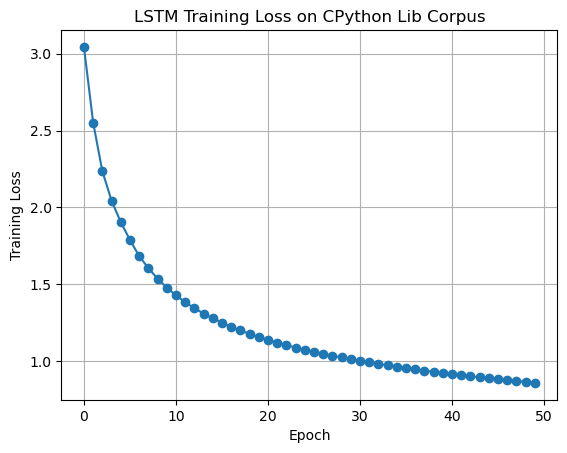

In [12]:
# Plot training loss over epochs
plt.figure()
plt.plot(history.history["loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("LSTM Training Loss on CPython Lib Corpus")
plt.grid(True)
plt.show()

## Rebuild model for regeneration

In [13]:
gen_model = build_model(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    rnn_units=rnn_units,
    batch_size=1
)

latest_ckpt = tf.train.latest_checkpoint(checkpoint_dir)
print("Loading weights from:", latest_ckpt)

gen_model.load_weights(latest_ckpt)
gen_model.build(tf.TensorShape([1, None]))

Loading weights from: ./checkpoints_cpython_lstm\ckpt_50


In [16]:
# Code generation function with temperature
def generate_code(start_string, num_chars=500, temperature=1.0):
    """
    Generate code starting from `start_string`.

    temperature < 1.0 → more conservative / repetitive
    temperature > 1.0 → more random / creative
    """
    # Vectorize start string
    input_ids = [char2idx.get(ch, 0) for ch in start_string]
    input_eval = tf.expand_dims(input_ids, 0)

    text_generated = []

    gen_model.reset_states()

    for _ in range(num_chars):
        predictions = gen_model(input_eval)
        # Remove batch dimension: (1, seq, vocab) → (seq, vocab)
        predictions = tf.squeeze(predictions, 0)
        # Take the last time step
        predictions = predictions[-1]

        # Adjust by temperature
        predictions = predictions / temperature

        # Sample from the categorical distribution
        predicted_id = tf.random.categorical(
            logits=tf.expand_dims(predictions, 0),
            num_samples=1
        )[0, 0].numpy()

        # Feed back the prediction as next input
        input_eval = tf.expand_dims([predicted_id], 0)

        text_generated.append(idx2char[predicted_id])

    return start_string + "".join(text_generated)

# Quick tests with different temperatures
print("=== Temperature 0.5 ===")
print(generate_code("def my_function(arg1, arg2):\n    ", num_chars=1000, temperature=0.5))

print("\n=== Temperature 1.0 ===")
print(generate_code("class MyClass:\n    def __init__(self):\n        ", num_chars=1000, temperature=1.0))


=== Temperature 0.5 ===
def my_function(arg1, arg2):
            return _('node_option_string]

    def __iter__(self):
        return _b32decode()
    formatter = self._local_evaluate_func()
        else:
            return False
                else:
                                                                                                                                                                                                                                                                                                                                                                                                               # None and the interactive validate type defaults to the interpreter.

        """
        if not callable(object):
        """Metavar functions that are considered a bytes objects of strings when a line objects or the
                                                                                                                                 